<a href="https://colab.research.google.com/github/onlinecitizen/zanzibar-malaria-importation-and/blob/main/MalariaImportation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Malaria Importation in Zanzibar**
**Introduction**

This notebook presents an analysis of malaria importation in Zanzibar, with a particular focus on the role of human mobility between Zanzibar and mainland Tanzania.
Malaria remains a significant public health challenge in Zanzibar, despite ongoing elimination efforts. One of the critical barriers to achieving elimination is the continuous movement of people:
- From Zanzibar to the mainland, where malaria transmission is higher.
- From the mainland back to Zanzibar, potentially reintroducing infections.


This is place where i am going to load and process data using wrangle function

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
def wrangle(filepath):
    df=pd.read_csv(filepath)
    df[['Year','Month']]=df['date'].str.split('-',expand=True)
    df=df.drop(columns='Year')
    return df

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df=wrangle('/content/drive/MyDrive/iLovePDF/dataset/ZIM_clinic_data - ZIM_clinic_data.csv.csv')

In [ ]:
df.head(10)

,deidentified_study_id,date,agegroup,sex,occupation,home_district,travel,travel_outside_shehia,travel_tz_district_primary,travel_tz_region_primary,travel_tz_reason,travel_over_4_nights,travel_over_14_nights,months_on_zb,mainlander_on_zb,Month
0,ZIM-02165065,2023-03,15 to 24,Male,Fishing,Unknown,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,03
1,ZIM-19546113,2022-05,40 and older,Male,Farming,Magharibi B,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,05
2,ZIM-09670992,2022-05,5 to 14,Male,Child (no occupation),Kati,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,05
3,ZIM-42826005,2022-05,25 to 39,Female,Farming,Kusini,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,05
4,ZIM-52271083,2022-05,Under 5,Female,Child (no occupation),Kati,1,0.0,Tabora,Tabora,Visiting family,1.0,0.0,<1,1.0,05
5,ZIM-96688201,2022-05,25 to 39,Male,Farming,Kati,1,0.0,Geita,Geita,Work,1.0,0.0,<1,1.0,05
6,ZIM-92162425,2022-05,25 to 39,Male,Farming,Kati,1,0.0,Kahama,Shinyanga,Work,1.0,0.0,NaN,0.0,05
7,ZIM-77574523,2022-05,40 and older,Male,Farming,Magharibi B,1,0.0,Tabora,Tabora,Visiting family,1.0,0.0,NaN,0.0,05
8,ZIM-72733767,2022-06,25 to 39,Male,Farming,Magharibi B,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,06
9,ZIM-28842011,2022-06,25 to 39,Male,Farming,Kati,1,0.0,Shinyanga,Shinyanga,Work,1.0,0.0,NaN,0.0,06


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3875 entries, 0 to 3874
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   deidentified_study_id       3875 non-null   object 
 1   date                        3859 non-null   object 
 2   agegroup                    3875 non-null   object 
 3   sex                         3869 non-null   object 
 4   occupation                  3832 non-null   object 
 5   home_district               3875 non-null   object 
 6   travel                      3875 non-null   int64  
 7   travel_outside_shehia       3700 non-null   float64
 8   travel_tz_district_primary  1100 non-null   object 
 9   travel_tz_region_primary    1099 non-null   object 
 10  travel_tz_reason            1021 non-null   object 
 11  travel_over_4_nights        1001 non-null   float64
 12  travel_over_14_nights       1001 non-null   float64
 13  months_on_zb                657 n

# **Dataset Overview**
- Total Entries: 3,875 rows
- Total Columns: 16
Column Properties
- Unique Identifier:
- The first column represents a unique ID for each person.
- Categorical Data:
- Most columns contain categorical variables.
- These are primarily represented as strings (e.g., names, categories) or binary values (0/1) indicating presence/absence or yes/no attributes.
- Numerical Data:
- One column, months on Zanzibar, contains integer values.
- This column likely represents the duration of stay or exposure time, which could be important for analysis.
Key Characteristics
- The dataset is dominated by categorical variables, making it suitable for:
- Frequency distribution analysis
- Cross-tabulation
- Logistic regression or classification models
- The binary columns (0/1) can be easily used for statistical summaries and predictive modeling.
- The integer column (months on Zanzibar) provides a continuous variable that can be used for correlation or regression analysis.


## Age Group Column


In [ ]:


agegroup=df['agegroup']
agegroup.head()

,agegroup
0,15 to 24
1,40 and older
2,5 to 14
3,25 to 39
4,Under 5


Age in This Datasets are categories into 5 groups which are under 5 years old ,5years old to 14 years old ,15 to 24 years old ,25 to 39 years old and 40 and older

In [ ]:
agegroupvc=agegroup.value_counts(normalize=True)
agegroupvc

,proportion
agegroup,
15 to 24,0.347097
25 to 39,0.316645
40 and older,0.161806
5 to 14,0.113032
Under 5,0.061419


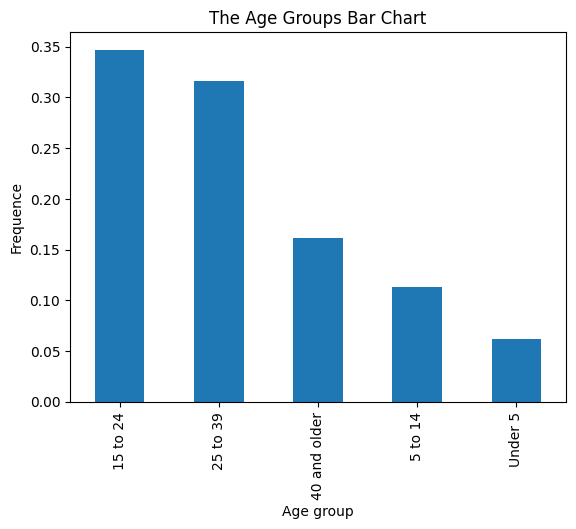

In [ ]:
agegroupvc.plot(kind='bar')
plt.title('The Age Groups Bar Chart')
plt.xlabel('Age group')
plt.ylabel('Frequence');

# **Malaria Cases by Age Group (Based on Bar Chart Analysis)**
The bar chart indicates that:

- Approximately 35% of malaria cases occur among individuals aged 15–24 years.
- Around 32.5% of cases are found in the 25–39 years age group.
- Those aged 40 years and above account for less than 20% of cases.
- Children under 15 years represent only a small proportion of cases.
From this distribution, it can be concluded that nearly 60% of malaria cases are concentrated among people aged 15–40 years. This trend may be attributed to the higher mobility of this age group, particularly their movement between Zanzibar and the mainland, compared to those below 14 years and above 40 years.


So  

# **Sex Categories and Malaria Cases in Zanzibar**

In [ ]:
sex=df['sex'].value_counts(normalize=True
                          )
sex

,proportion
sex,
Male,0.673042
Female,0.326958



Analysis of the dataset shows that 67.3% of malaria cases in Zanzibar are male, while 32.7% are female.
This imbalance suggests that men are disproportionately affected by malaria in Zanzibar. One possible explanation is that men are more likely to engage in frequent mobility between Zanzibar and the mainland, whether for work, trade, or travel. Such movement increases the risk of malaria importation and highlights how mobility can hinder elimination efforts


From this let group sex using agegroup

# **Sex and Age Group Distribution of Malaria Cases**

In [ ]:
sex_age=(pd.DataFrame(df['sex']
                      .groupby(df['agegroup'])
                      .value_counts(normalize=True))
         .reset_index()
         .rename({'portion':'frequency'}))
sex_age.head()

,agegroup,sex,proportion
0,15 to 24,Male,0.663440
1,15 to 24,Female,0.336560
2,25 to 39,Male,0.730392
3,25 to 39,Female,0.269608
4,40 and older,Male,0.749201


In [ ]:
dict={'under 5':0,'5 to 14':1,'15 to 24':2,'25 to 39':3,'40 and older':4}

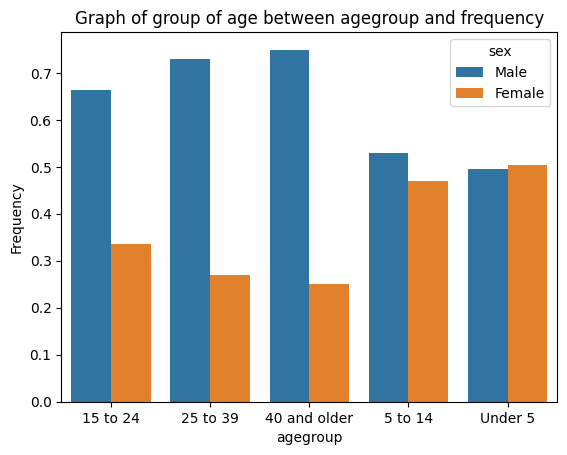

In [ ]:
sns.barplot(data=sex_age,x='agegroup',y='proportion',hue='sex')
plt.title('Graph of group of age between agegroup and frequency')
plt.ylabel('Frequency');


The chart reveals important patterns in malaria cases across age groups when disaggregated by sex:
- Under 5 years: Female children appear to have a slightly higher frequency of malaria cases compared to male children.
- All other age groups: Male cases dominate across the board.
- Ages 15–40 years: Male cases account for more than 60% of malaria infections in this age range, significantly exceeding female cases.
Key Insight
This distribution suggests that adult men in the 15–40 age group are the primary contributors to malaria cases in Zanzibar. Given that this age group is also the most mobile—frequently traveling between Zanzibar and the mainland—their higher infection rates reinforce the idea that mobility is a major driver of malaria importation.


#Occupations Reported Among Malaria Cases
Now let's explore the occupation column to see how is it

In [ ]:
print(f'Number of occupation {df['occupation'].nunique()}')

Number of occupation 12


In [ ]:
df['occupation'].unique()

array(['Fishing', 'Farming', 'Child (no occupation)', 'Other',
       'Trader/business', 'Construction', 'Public servant/NGO',
       'Housewife', 'Watchman/security', 'Food service', 'Tourism',
       'Student', nan], dtype=object)


The dataset records the occupation of individuals who reported malaria. There are 12 main job categories most frequently mentioned:
- Fishing
- Farming
- Child (no occupation)
- Other
- Trader/Business
- Construction
- Public Servant/NGO
- Housewife
- Watchman/Security
- Food Service
- Tourism
- Student



In [ ]:
occu_data=pd.DataFrame(df['occupation'].groupby(df['sex']).value_counts(normalize=True).rename('frequency')).reset_index()
occu_data.head()

,sex,occupation,frequency
0,Female,Child (no occupation),0.300878
1,Female,Housewife,0.259377
2,Female,Trader/business,0.114924
3,Female,Farming,0.094972
4,Female,Other,0.079808


In [ ]:
mask=df['occupation']=='Housewife'
mks=df['sex']=='Male'
df[mask & mks].shape

(16, 16)

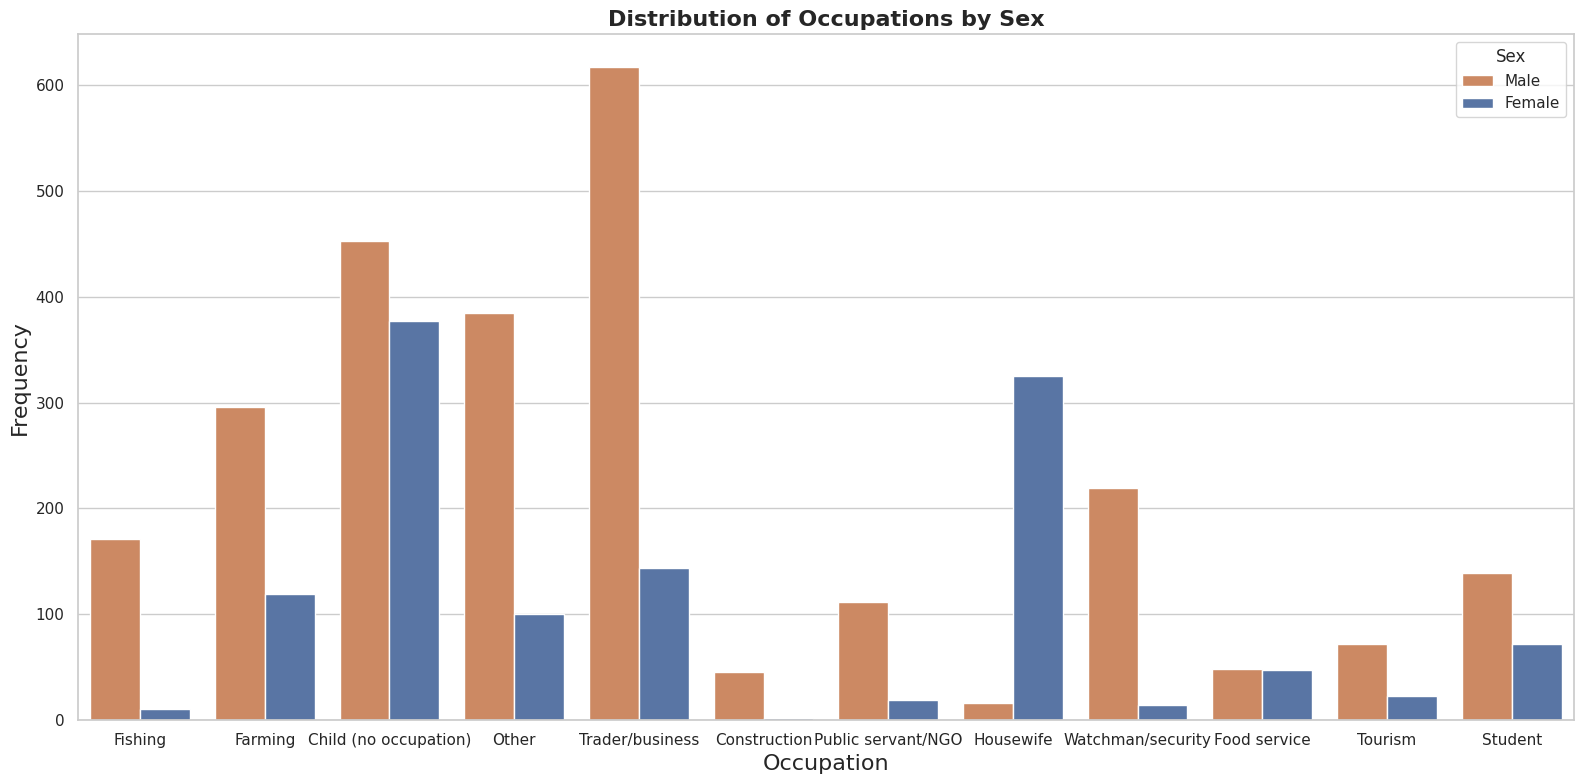

In [ ]:


plt.figure(figsize=(16, 8))
sns.set(style="whitegrid")
palette = {"Female": "#4C72B0", "Male": "#DD8452"}

sns.countplot(data=df, x="occupation", hue="sex", palette=palette)

plt.title("Distribution of Occupations by Sex", fontsize=16, weight='bold')
plt.xlabel("Occupation", fontsize=16)
plt.ylabel("Frequency", fontsize=16)
plt.legend(title="Sex", loc="upper right")
plt.tight_layout()
plt.show()

# **Occupational Distribution of Malaria Cases**
The chart reveals that malaria cases in Zanzibar are reported across a range of occupations, with the following ranked by frequency:
- Trader/Business
- Child (no occupation)
- Other (unknown occupation)
- Watchman/Security
- Fishing
- Student
- Construction

**Gender Insights**
- The Housewife category stands out as the most frequent occupation among female malaria cases, reflecting household exposure risks.
- Across all other occupations, male cases consistently outnumber female cases, indicating that men are more affected overall.
- This pattern reinforces earlier observations that mobility and occupational exposure—especially among men—play a significant role in malaria transmission and importation.


# **Home District of Reported Malaria Cases**
The dataset includes a column for home district, which identifies where each individual reporting malaria originates. This variable is important because:
- It allows us to map malaria cases geographically across Zanzibar and the mainland.
- We can analyze whether certain districts contribute disproportionately to malaria importation.
- It helps connect mobility patterns (movement between districts and across Zanzibar–mainland routes) with malaria persistence.


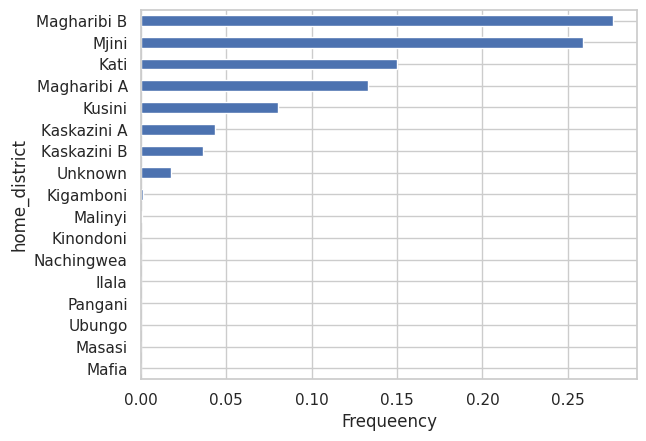

In [ ]:
df['home_district'].value_counts(normalize=True).sort_values().plot(kind='barh')
plt.xlabel('Frequeency');


The horizontal bar chart shows the distribution of malaria cases according to individuals’ home districts.
Key Findings

**Within Zanzibar**:
- The districts with the highest frequency of reported malaria cases are Magharib B, Mjini, and Kati, each accounting for more than 15% of all cases.
- Other districts such as Magharib A, Kaskazini A, Kaskazini B, and Unknown also contribute significantly, each covering more than 5% of reported cases.

**Outside Zanzibar**:
- A smaller but notable number of cases are linked to individuals whose home districts are on the mainland, including Kigamboni, Malinyi, Kinondoni, Nachingwea, Ilala, Pangani, Ubungo, Masasi, and Mafia.
**Insight**

This distribution highlights that the majority of malaria cases originate from people whose home districts are within Zanzibar, particularly concentrated in Magharib B, Mjini, and Kati. However, the presence of cases from mainland districts underscores the role of importation through mobility as a continuing challenge for malaria elimination in Zanzibar.


From the chart we have got to know that ,more than 54% people who have case of malaria their home district  is  magharibi B or Mjini discrit
15% kati greater tahn 13% are from Magharib A more than 7% from usini remain are less than 5%

From this now we are  goping to do father analysis to see why the people ages btn

In [ ]:
df.head()

,deidentified_study_id,date,agegroup,sex,occupation,home_district,travel,travel_outside_shehia,travel_tz_district_primary,travel_tz_region_primary,travel_tz_reason,travel_over_4_nights,travel_over_14_nights,months_on_zb,mainlander_on_zb,Month
0,ZIM-02165065,2023-03,15 to 24,Male,Fishing,Unknown,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,03
1,ZIM-19546113,2022-05,40 and older,Male,Farming,Magharibi B,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,05
2,ZIM-09670992,2022-05,5 to 14,Male,Child (no occupation),Kati,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,05
3,ZIM-42826005,2022-05,25 to 39,Female,Farming,Kusini,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,05
4,ZIM-52271083,2022-05,Under 5,Female,Child (no occupation),Kati,1,0.0,Tabora,Tabora,Visiting family,1.0,0.0,<1,1.0,05


In [ ]:
df['months_on_zb'].unique()

array([nan, '<1', '1 to 3', '3 to 6', '>6'], dtype=object)

In [ ]:
df['mainlander_on_zb'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 3875 entries, 0 to 3874
Series name: mainlander_on_zb
Non-Null Count  Dtype  
--------------  -----  
3867 non-null   float64
dtypes: float64(1)
memory usage: 30.4 KB


In [ ]:
df['mainlander_on_zb'].unique()

array([ 0.,  1., nan])

In [ ]:
df['travel_over_14_nights'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 3875 entries, 0 to 3874
Series name: travel_over_14_nights
Non-Null Count  Dtype  
--------------  -----  
1001 non-null   float64
dtypes: float64(1)
memory usage: 30.4 KB


In [ ]:
df['travel_over_14_nights'].unique()

array([nan,  0.,  1.])

In [ ]:
df['travel_over_4_nights'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 3875 entries, 0 to 3874
Series name: travel_over_4_nights
Non-Null Count  Dtype  
--------------  -----  
1001 non-null   float64
dtypes: float64(1)
memory usage: 30.4 KB


In [ ]:
df['travel_over_14_nights'].unique()

array([nan,  0.,  1.])

In [ ]:
df['travel_tz_reason'].unique()

array([nan, 'Visiting family', 'Work', 'Other', 'Vacation'], dtype=object)

In [ ]:
len(df['travel_tz_region_primary'].unique())

26

In [ ]:
df['travel_tz_region_primary'].unique()

array([nan, 'Tabora', 'Geita', 'Shinyanga', 'Simiyu', 'Tanga',
       'Dar Es Salaam', 'Mara', 'Pwani', 'Dodoma', 'Morogoro', 'Ruvuma',
       'Mtwara', 'Kigoma', 'Kagera', 'Lindi', 'Mwanza', 'Rukwa',
       'Singida', 'Arusha', 'Unknown', 'Songwe', 'Mbeya', 'Kilimanjaro',
       'Manyara', 'Katavi'], dtype=object)

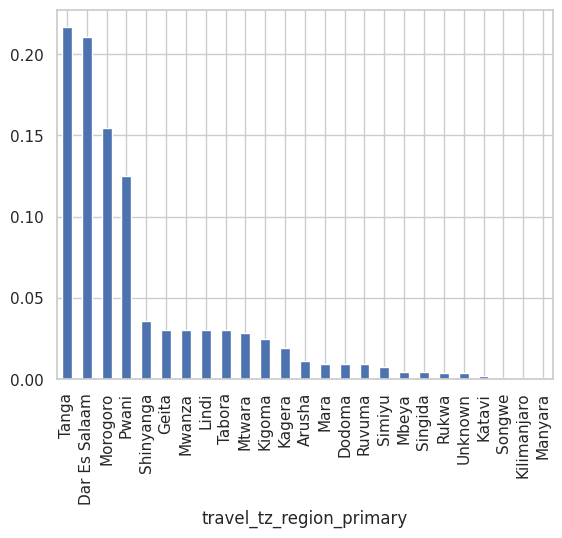

In [ ]:
df['travel_tz_region_primary'].value_counts(normalize=True).plot(kind='bar');

<Axes: xlabel='travel_tz_district_primary'>

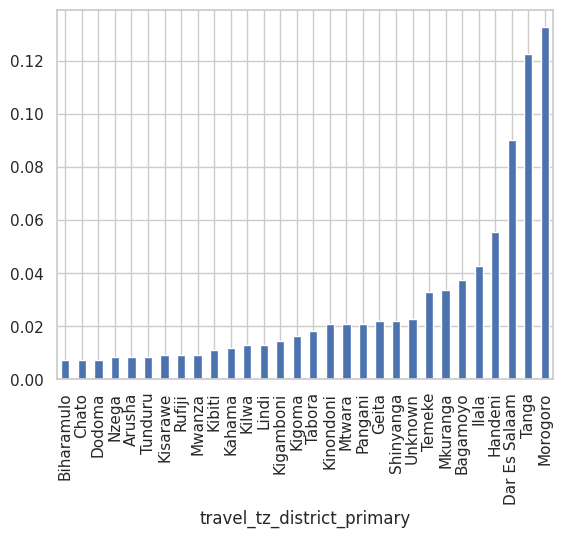

In [ ]:
df['travel_tz_district_primary'].value_counts(normalize=True).sort_values().tail(30).plot(kind='bar')

# **Seasonal Malaria Case Patterns in Zanzibar (2022–2024)**



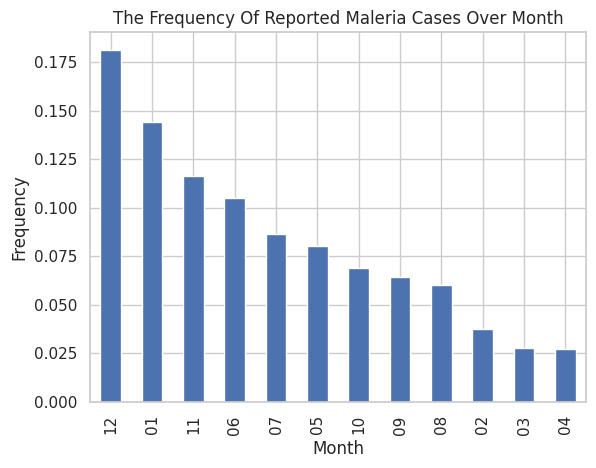

In [ ]:
df['Month'].value_counts(normalize=True).plot(kind='bar')
plt.ylabel('Frequency')
plt.title('The Frequency Of Reported Maleria Cases Over Month');

**Observed Groupings**

Analysis of malaria case reports shows a recurring four‑season pattern:
- November–January: Highest peak in cases.
- May–July: Second major peak.
- August–October: Moderate rise.
- February–April: Smaller but consistent wave.

**Why This Happens**
- Rainfall cycles: Zanzibar experiences two rainy seasons (Vuli in Oct–Dec and Masika in Mar–May). Heavy rains create breeding sites for Anopheles mosquitoes, leading to surges in transmission shortly after.
- Residual transmission: Mosquito populations remain high for weeks after rains, sustaining smaller waves in Feb–Apr and Aug–Oct.
- Imported infections: Many cases are linked to travel from mainland Tanzania, especially during holidays and seasonal labor migration, which amplifies peaks around December and mid‑year.
- Vector control timing: Indoor residual spraying (IRS) and bed net campaigns are scheduled seasonally. Gaps in coverage can allow transmission to rise during rainy months.
- 2023–2024 outbreak: Over 23,500 confirmed cases were reported between Nov 2023–Mar 2024, driven by climate variability, delayed interventions, and increased imported cases.

In [ ]:
df.columns

Index(['deidentified_study_id', 'date', 'agegroup', 'sex', 'occupation',
       'home_district', 'travel', 'travel_outside_shehia',
       'travel_tz_district_primary', 'travel_tz_region_primary',
       'travel_tz_reason', 'travel_over_4_nights', 'travel_over_14_nights',
       'months_on_zb', 'mainlander_on_zb', 'Month'],
      dtype='object')

In [ ]:
df['travel_outside_shehia'].unique()

array([ 0.,  1., nan])

df[df['travel_outside_shehia']==1.]

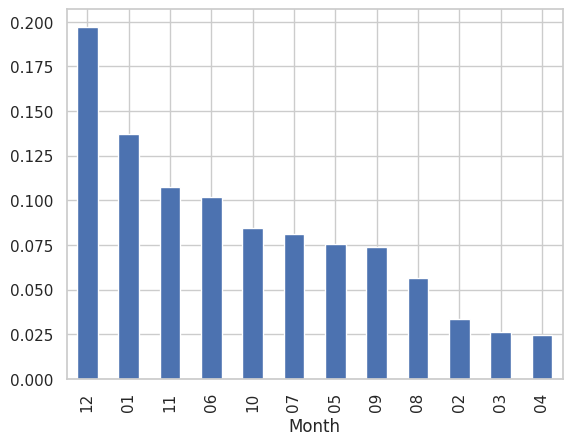

In [ ]:
df_outside=df[df['travel_outside_shehia']==1.]['Month'].value_counts(normalize=True).plot(kind='bar')

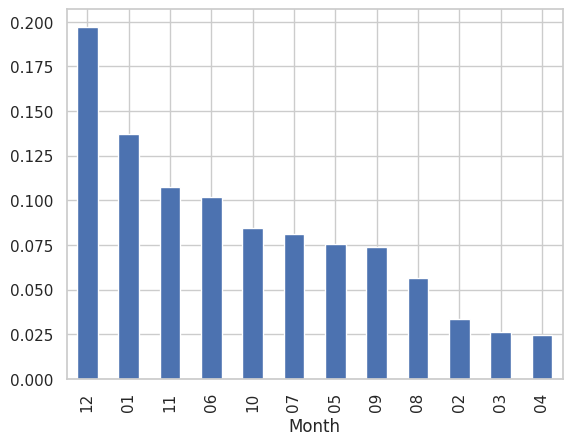

In [ ]:

df_outside = df[df['travel_outside_shehia']==1.]
df_outside['Month'].value_counts(normalize=True).plot(kind='bar')
share = df_outside.shape[0]/df.shape[0]*100